# SVHN 이미지 다중분류 실습문제

실제 거리 사진에서 숫자 이미지를 입력받아 0부터 9까지 10개의 숫자 중 하나로 분류하는 CNN(합성곱 신경망)을 구현하시오.

- 데이터셋: SVHN (Street View House Numbers)
- 학습 데이터: 73,257개
- 테스트 데이터: 26,032개
- 추가 데이터: 531,131개 (이번 실습에서는 사용하지 않음)
- 이미지 크기: 32 × 32


| 구분 | 내용 |
|---|---|
| 데이터 | SVHN |
| 입력 데이터 | RGB 이미지 |
| 입력 Shape | `(3, 32, 32)` |
| 출력 데이터 | 10개 클래스 |
| 정답 레이블 | 0~9 |
| 손실함수 | `CrossEntropyLoss` |
| Optimizer | Adam |

In [1]:
# function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
# import importlib
# import multiclass_functions
# importlib.reload(multiclass_functions)

from multiclass_functions import *

In [2]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#### STEP 1. 라이브러리 불러오기 및 실행 환경 확인

**실습 조건**

| 변수 | 값 |
|---|---:|
| `BATCH_SIZE` | 64 |
| `EPOCH` | 10 |
| `LR` | 0.001 |
| `IMAGE_SIZE` | 32 |

In [3]:
BATCH_SIZE = 64
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
IMAGE_SIZE = 32

criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN'
dataset = 'SVHN'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

#### STEP 2. 데이터 다운로드 및 데이터셋 확인

**문제**

1. `torchvision.datasets.SVHN`을 이용하여 학습 데이터를 다운로드하시오.
2. 테스트 데이터를 다운로드하시오.
3. `split="train"`과 `split="test"`를 구분하여 사용하시오.
4. 학습 데이터와 테스트 데이터의 개수를 출력하시오.
5. 이미지와 정답 레이블의 구조를 확인하시오.

**주의** SVHN 데이터셋에서는 숫자 0의 레이블이 10으로 저장되어 있다. 모델에서 사용할 클래스 번호 0~9에 맞도록 변환하여 사용

#### STEP 3. 이미지 전처리 및 DataLoader 생성

**전처리 조건**

- `transforms.Compose()`를 이용하여 이미지 전처리를 구성한다.
- `transforms.ToTensor()`를 적용한다.
- 이미지 픽셀 값은 0~1 범위로 변환한다.( Scaling )
- 이미지 크기는 32 × 32를 유지한다.
- 학습 데이터와 테스트 데이터에 동일한 전처리를 적용한다.
- 학습 데이터 중 20%를 검증 데이터로 분리한다.

**문제**

1. 이미지 전처리를 구성하시오.
2. 학습 데이터와 테스트 데이터에 전처리를 적용하시오.
3. SVHN의 정답 레이블 10을 0으로 변환하시오.
4. 학습 데이터의 20%를 검증 데이터로 분리하시오.
5. 학습·검증·테스트용 `DataLoader`를 생성하시오.
6. 학습 데이터는 `shuffle=True`, 검증 및 테스트 데이터는 `shuffle=False`로 설정하시오.
7. 첫 번째 배치의 이미지와 정답 레이블 shape를 출력하시오.
8. 이미지 9장을 정답 레이블과 함께 시각화하시오.

**주의:** SVHN 데이터셋에는 `classes` 속성이 기본 제공되지 않는다. 숫자 클래스 이름 목록을 준비하여 시각화 및 혼동행렬에 활용하시오.

In [ ]:
# 이미지 전처리 구정(autoaugment, totensor)
transform = transforms.Compose([
    transforms.AutoAugment(transforms.AutoAugmentPolicy.SVHN),
    transforms.ToTensor()
])

train_DS = datasets.SVHN(root='data', split='train', download=True, transform=transform)
test_DS = datasets.SVHN(root='data', split='test', download=True, transform=transform)

In [5]:
# 정답 레이블명 변경
train_DS.classes=[str(i)for i in range(10)]
test_DS.classes=[str(i) for i in range(10)]

In [6]:
x, y = train_DS[0]

print('Train size :', len(train_DS))
print('Test size  :', len(test_DS))
print('Image shape:', x.shape)
print('Image dtype:', x.dtype)
print('Label      :', y)
print('n_class    :', len(train_DS.classes))

Train size : 73257
Test size  : 26032
Image shape: torch.Size([3, 32, 32])
Image dtype: torch.float32
Label      : 1
n_class    : 10


In [7]:
split_idx = int(len(train_DS) * 0.8)

x_train = train_DS.data[:split_idx]
x_val = train_DS.data[split_idx:]

y_train = train_DS.labels[:split_idx]
y_val = train_DS.labels[split_idx:]

In [8]:
x_train_ts = torch.tensor(x_train, dtype=torch.float32) / 255.
x_val_ts = torch.tensor(x_val, dtype=torch.float32) / 255.

y_train_ts = torch.tensor(y_train, dtype=torch.long)
y_val_ts = torch.tensor(y_val, dtype=torch.long)

train_subset = TensorDataset(x_train_ts, y_train_ts)
val_subset = TensorDataset(x_val_ts, y_val_ts)

In [9]:
train_DL = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_DL = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_DL = DataLoader(
    test_DS,
    batch_size=BATCH_SIZE,
    shuffle=False
)

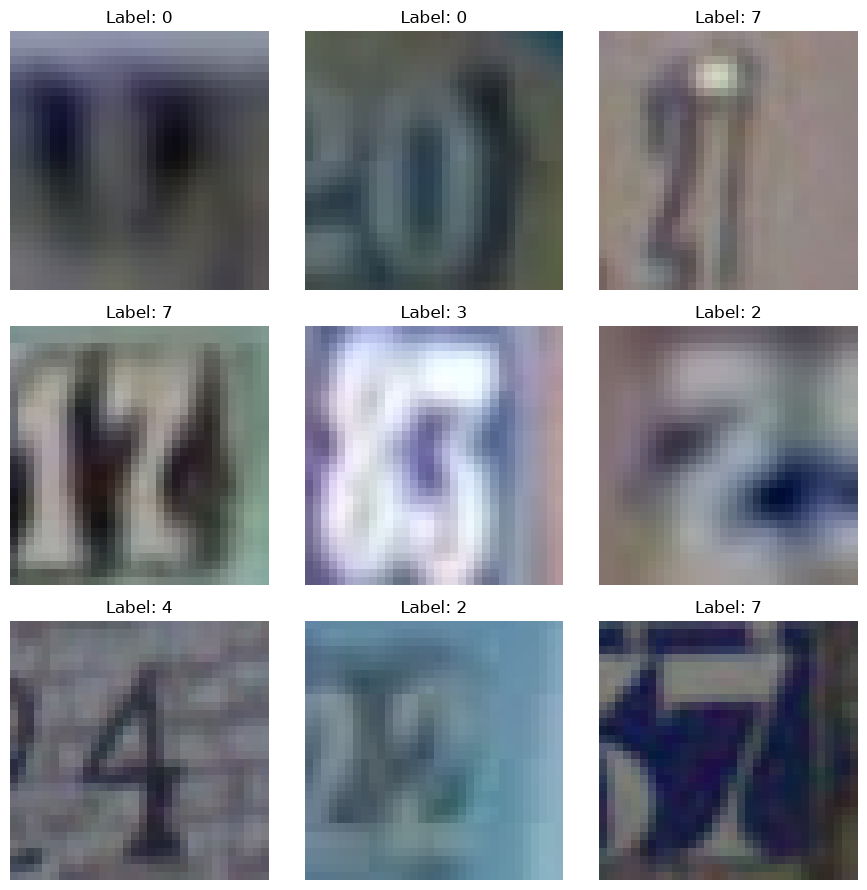

In [10]:
x_batch, y_batch = next(iter(train_DL))

plt.figure(figsize=(9, 9))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_batch[i].permute(1, 2, 0))
    plt.title(f'Label: {y_batch[i].item()}')
    plt.axis('off')

plt.tight_layout()
plt.show()

#### STEP 4. CNN 모델 만들기

**목표:** 이미지에서 숫자의 특징을 추출하는 CNN 모델을 구성한다.

**모델 조건**

- 입력: 3채널 RGB 이미지, 크기 32×32
- 첫 번째 합성곱 층: 3 → 32 채널, 커널 3×3, padding=1
- 두 번째 합성곱 층: 32 → 64 채널, 커널 3×3, padding=1
- 세 번째 합성곱 층: 64 → 128 채널, 커널 3×3, padding=1
- 각 합성곱 층 뒤에 ReLU와 2×2 MaxPool을 적용한다.
- `AdaptiveAvgPool2d((1, 1))`로 특징맵 크기를 1×1로 맞춘다.
- Flatten 후 완전연결(fullconnect)층을 적용한다.
- 출력층: `Linear(128, 10)`

**문제**

1. `nn.Module`을 상속받아 CNN 클래스를 정의하시오.
2. `forward()` 함수를 구현하시오.
3. 모델을 생성하고 `DEVICE`로 이동하시오.
4. 모델 구조를 출력하시오.
5. 임의의 입력 5장으로 출력 shape를 확인하시오. 결과는 `(5, 10)`이어야 한다.

In [11]:
class CNN(nn.Module):
    def __init__(self,*args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(nn.Conv2d(3,32,3,padding=1),
                                   nn.BatchNorm2d(32),
                                   nn.ReLU(),
                                   nn.Dropout(.2)
                                   )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(nn.Conv2d(32,64,3,padding=1),
                                   nn.BatchNorm2d(64),
                                   nn.ReLU(),
                                   nn.Dropout(.2)
                                   )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(nn.Conv2d(64,128,3,padding=1),
                                   nn.BatchNorm2d(128),
                                   nn.ReLU(),
                                   nn.Dropout(.2)
                                   )
        self.maxpool3 = nn.MaxPool2d(2)
        self.adaptpool = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(128,10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = self.adaptpool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [12]:
model = globals()[model_type]().to(device)

# 모델 구조 출력
model.eval()

x_batch, y_batch = next(iter(train_DL))
x_batch = x_batch.to(DEVICE)

with torch.no_grad():
    conv1 = model.conv1(x_batch)
    conv2 = model.conv2(model.maxpool1(conv1))
    conv3 = model.conv3(model.maxpool2(conv2))
    flat = torch.flatten(model.adaptpool(model.maxpool3(conv3)), start_dim=1)
    fc = model.fc(flat)

print('Input   :', x_batch.shape)
print('Conv1   :', conv1.shape)
print('Conv2   :', conv2.shape)
print('Conv3   :', conv3.shape)
print('Flatten :', flat.shape)
print('Output  :', fc.shape)

Input   : torch.Size([64, 3, 32, 32])
Conv1   : torch.Size([64, 32, 32, 32])
Conv2   : torch.Size([64, 64, 16, 16])
Conv3   : torch.Size([64, 128, 8, 8])
Flatten : torch.Size([64, 128])
Output  : torch.Size([64, 10])


#### STEP 5. 모델 학습시키기

**학습 조건**

- Loss function: `nn.CrossEntropyLoss()`
- Optimizer: `optim.Adam()`
- Learning Rate: `0.001`
- Epoch: 10
- Batch size: 64

**문제**

1. 손실함수를 정의하시오.
2. Optimizer를 정의하시오.
3. `multiclass_functions.py`의 `Train()` 함수를 이용하여 모델을 학습시키시오.
4. Epoch별 평균 Train Loss를 기록하시오.
5. 학습 Loss 그래프를 시각화하시오.

In [13]:
def train(dataloader, model, loss_fn, optimizer, device):

    size = len(dataloader.dataset)

    model.train()
    rloss = 0

    for x_train_ts, y_train_ts in dataloader:
        x, y = x_train_ts.to(device), y_train_ts.to(device)

        pred = model(x)
        loss = loss_fn(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_b = loss.item() * x.shape[0]
        rloss += loss_b

    loss_e = rloss / size

    return loss_e

In [14]:
def evaluate(dataloader, model, loss_fn, device):
    model.eval()
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x_val_ts.to(device), y_val_ts.to(device)
            pred = model(x)
            val_loss = loss_fn(pred, y).item()
    return val_loss, pred

In [15]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label='train error', marker='.')
    plt.plot(epochs, val_loss_list, label='val error', marker='.')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.legend()
    plt.show()

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=LR)
tr_loss_list, val_loss_list = [], []
if new_model_train:
    for ep in range(EPOCH):
        tr_loss = train(train_DL, model, criterion, optimizer, device)
        val_loss, _ = evaluate(val_DL, model, criterion, device)
        tr_loss_list.append(tr_loss)
        val_loss_list.append(val_loss)
        print(f'Ep {ep+1}, TL {tr_loss:.4f}, VL {val_loss:.4f}')

    torch.save(model, save_model_path)
    learning_curve(tr_loss_list, val_loss_list)


Ep 1, TL 1.6397, VL 1.4792


#### STEP 6. 모델 저장 및 불러오기

**문제**

1. 학습이 끝난 모델의 `state_dict()`를 `results` 폴더에 저장하시오.
2. 동일한 CNN 구조를 새로 생성하시오.
3. 저장한 가중치를 `torch.load(..., map_location=DEVICE)`로 불러오시오.
4. 새 모델에 `load_state_dict()`를 적용하시오.
5. 불러온 모델을 `DEVICE`로 이동하고 `eval()` 모드로 전환하시오.

저장 파일명 예시: `CNN_SVHN.pt`

In [ ]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

#### STEP 7. 모델 테스트하기

**문제**

1. 불러온 모델을 이용하여 테스트 데이터의 예측값을 계산하시오.
2. `torch.no_grad()`를 이용하여 추론하시오.
3. `argmax(dim=1)`로 예측 클래스를 구하시오.
4. `multiclass_functions.py`의 `Test()` 함수를 이용하여 테스트 정확도를 계산하시오.
5. 정답 개수와 전체 테스트 데이터 개수를 출력하시오.

In [ ]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 23034 / 26032 (88.5 %)
94986


#### STEP 8. 테스트 결과 시각화

**문제**

1. 테스트 이미지 6장을 시각화하시오.
2. 각 이미지의 실제 정답과 예측 결과를 표시하시오.
3. 정답과 예측이 다르면 제목을 빨간색으로 표시하시오.

**주의:** SVHN은 기본적으로 `classes` 속성을 제공하지 않으므로 숫자 클래스 이름 목록을 사용하시오.

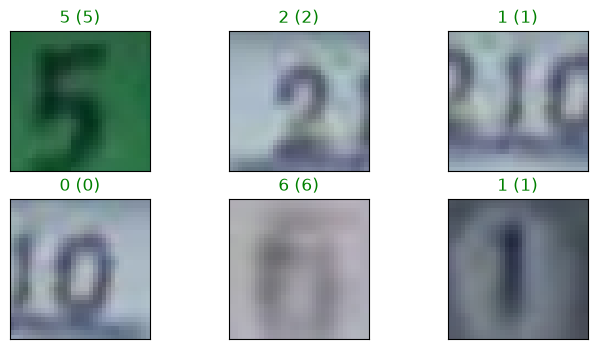

In [ ]:
Test_plot(load_model, test_DL)

#### STEP 9. 혼동행렬 및 오분류 이미지 분석

**문제 1. Confusion Matrix**

1. `plot_confusion_matrix()` 함수를 이용하여 혼동행렬을 시각화하시오.
2. 행(Row)은 실제 클래스, 열(Column)은 예측 클래스로 표시하시오.
3. 숫자별 정답 개수와 오분류 개수를 확인하시오.

**문제 2. 오분류 이미지 확인**

1. 테스트 데이터에서 실제 정답과 예측값이 다른 인덱스를 찾으시오.
2. 오분류 이미지 중 최대 9장을 시각화하시오.
3. 이미지 위에 실제 정답과 예측값을 표시하시오.
4. 오분류 이미지가 없으면 '오분류 이미지가 없습니다'를 출력하시오.

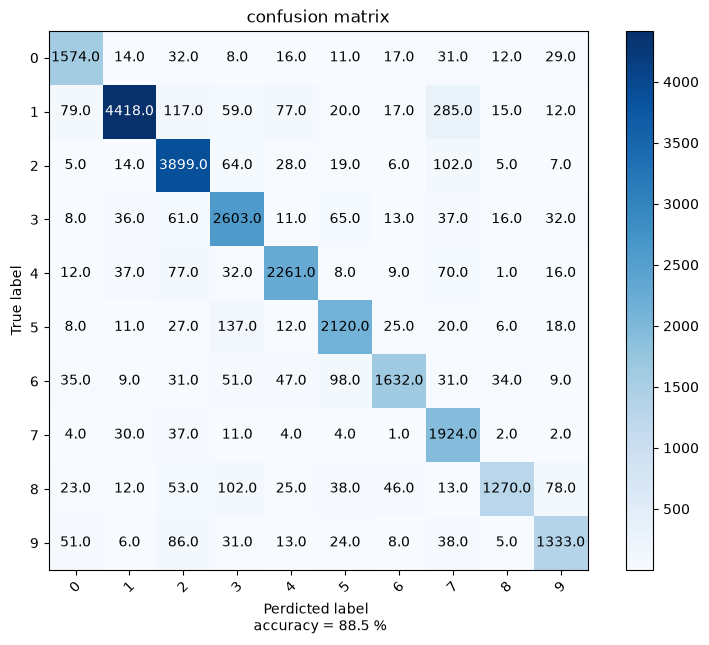

In [ ]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion, test_DS.classes)

plt.xticks(rotation=45);

#### STEP 10. 파라미터 개수 확인

**문제**

1. 학습 가능한 전체 파라미터 개수를 출력하시오.
2. Conv2d와 Linear 계층의 파라미터 개수를 각각 확인하시오.
3. CNN 모델의 학습 가능한 파라미터가 어느 계층에 많이 분포하는지 확인하시오.

In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f'Total parameters     : {total_params:,}')
print(f'Trainable parameters : {trainable_params:,}')

Total parameters     : 94,986
Trainable parameters : 94,986


#### Baseline 모델의 학습 성능을 분석하고 최적의 Hyperparameter를 찾는 단계

In [ ]:
def learning_summary(tr_loss_list, val_loss_list):

    best_idx = np.argmin(val_loss_list)

    print(f'Total Epoch     : {len(tr_loss_list)}')
    print(f'Initial TL      : {tr_loss_list[0]:.4f}')
    print(f'Initial VL      : {val_loss_list[0]:.4f}')
    print(f'Final TL        : {tr_loss_list[-1]:.4f}')
    print(f'Final VL        : {val_loss_list[-1]:.4f}')
    print(f'Best VL         : {val_loss_list[best_idx]:.4f}')
    print(f'Best Epoch      : {best_idx + 1}')
    print(f'Final Loss Gap  : {val_loss_list[-1] - tr_loss_list[-1]:.4f}')

learning_summary(tr_loss_list, val_loss_list)

Total Epoch     : 10
Initial TL      : 1.5614
Initial VL      : 1.1624
Final TL        : 0.2848
Final VL        : 0.4021
Best VL         : 0.4021
Best Epoch      : 10
Final Loss Gap  : 0.1173


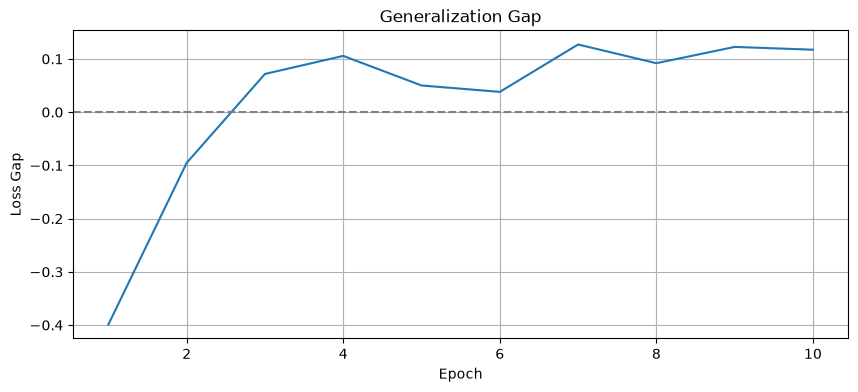

In [ ]:
loss_gap = np.array(val_loss_list) - np.array(tr_loss_list)

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(loss_gap) + 1), loss_gap)
plt.axhline(y=0, color='gray', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss Gap')
plt.title('Generalization Gap')
plt.grid()
plt.show()  # 3번째 epoch에서 모델 성능이 가장 뛰어났음을 확인

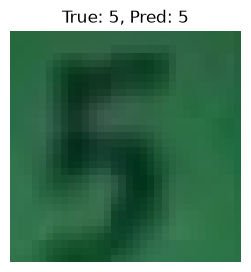

In [ ]:
# 분석 대상 이미지 선택
load_model.eval()

x_batch, y_batch = next(iter(test_DL))

idx = 0

image = x_batch[idx:idx+1].to(device)
true_label = y_batch[idx].item()

with torch.no_grad():
    y_hat = load_model(image)
    pred_label = y_hat.argmax(dim=1).item()

plt.figure(figsize=(3, 3))
plt.imshow(image[0].cpu().permute(1, 2, 0))
plt.title(f'True: {true_label}, Pred: {pred_label}')
plt.axis('off')
plt.show()

In [ ]:
# Feature Map 추출
load_model.eval()

with torch.no_grad():

    feature_map1 = load_model.conv1(image)

    feature_map2 = load_model.conv2(
        load_model.maxpool1(feature_map1)
    )

    feature_map3 = load_model.conv3(
        load_model.maxpool2(feature_map2)
    )

print('Feature Map 1:', feature_map1.shape)
print('Feature Map 2:', feature_map2.shape)
print('Feature Map 3:', feature_map3.shape)

Feature Map 1: torch.Size([1, 32, 32, 32])
Feature Map 2: torch.Size([1, 64, 16, 16])
Feature Map 3: torch.Size([1, 128, 8, 8])


In [ ]:
# 개별 채널 Feature Map 시각화
def plot_feature_maps(feature_map, title, n_cols=8):

    feature_map = feature_map[0].detach().cpu()

    n_channels = feature_map.shape[0]
    n_rows = (n_channels + n_cols - 1) // n_cols

    plt.figure(figsize=(n_cols * 2, n_rows * 2))

    for i in range(n_channels):
        plt.subplot(n_rows, n_cols, i+1)
        plt.imshow(feature_map[i], cmap='viridis')
        plt.title(f'Ch {i}')
        plt.axis('off')

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

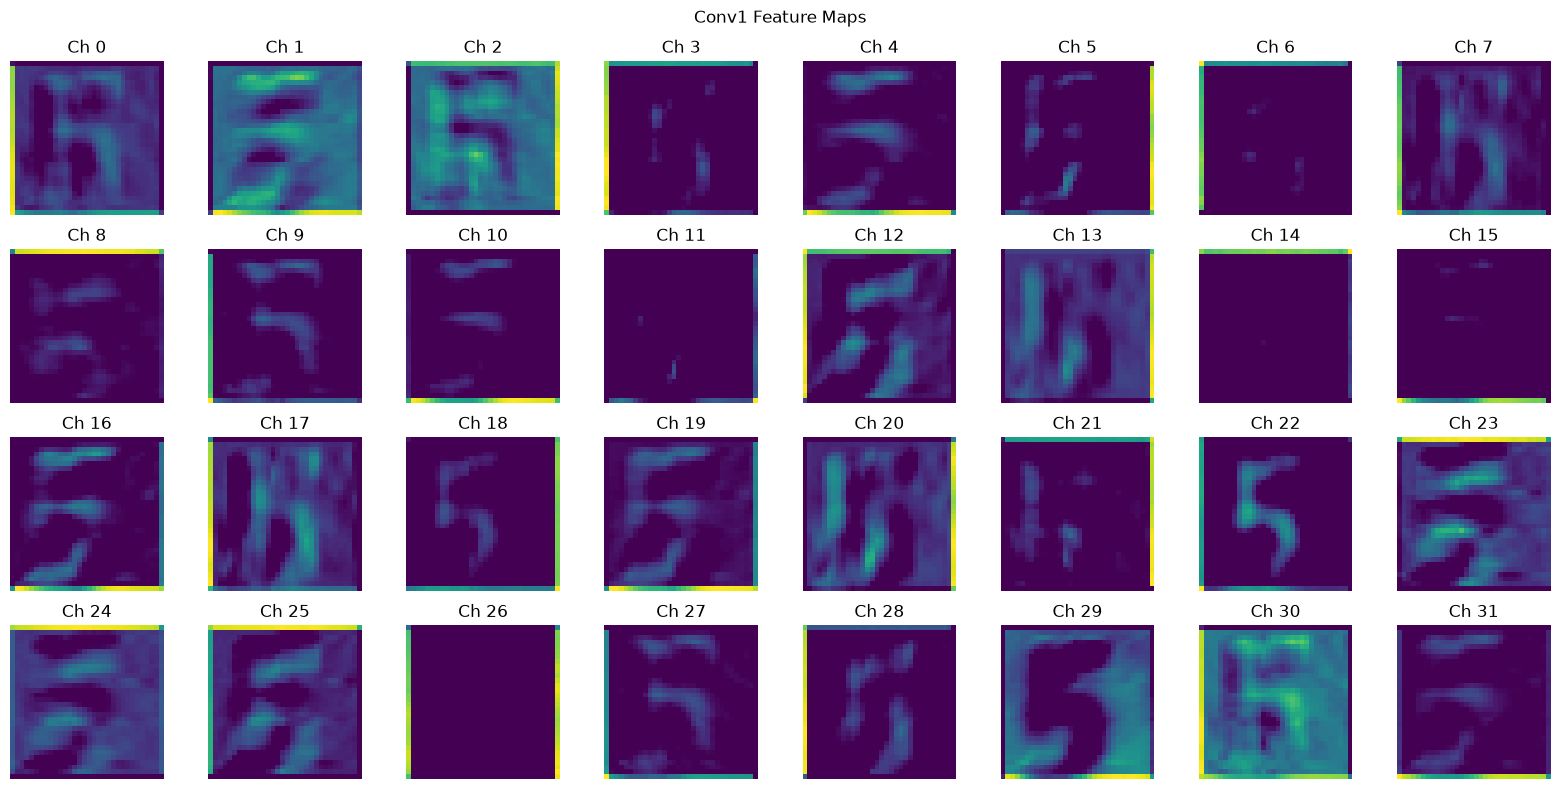

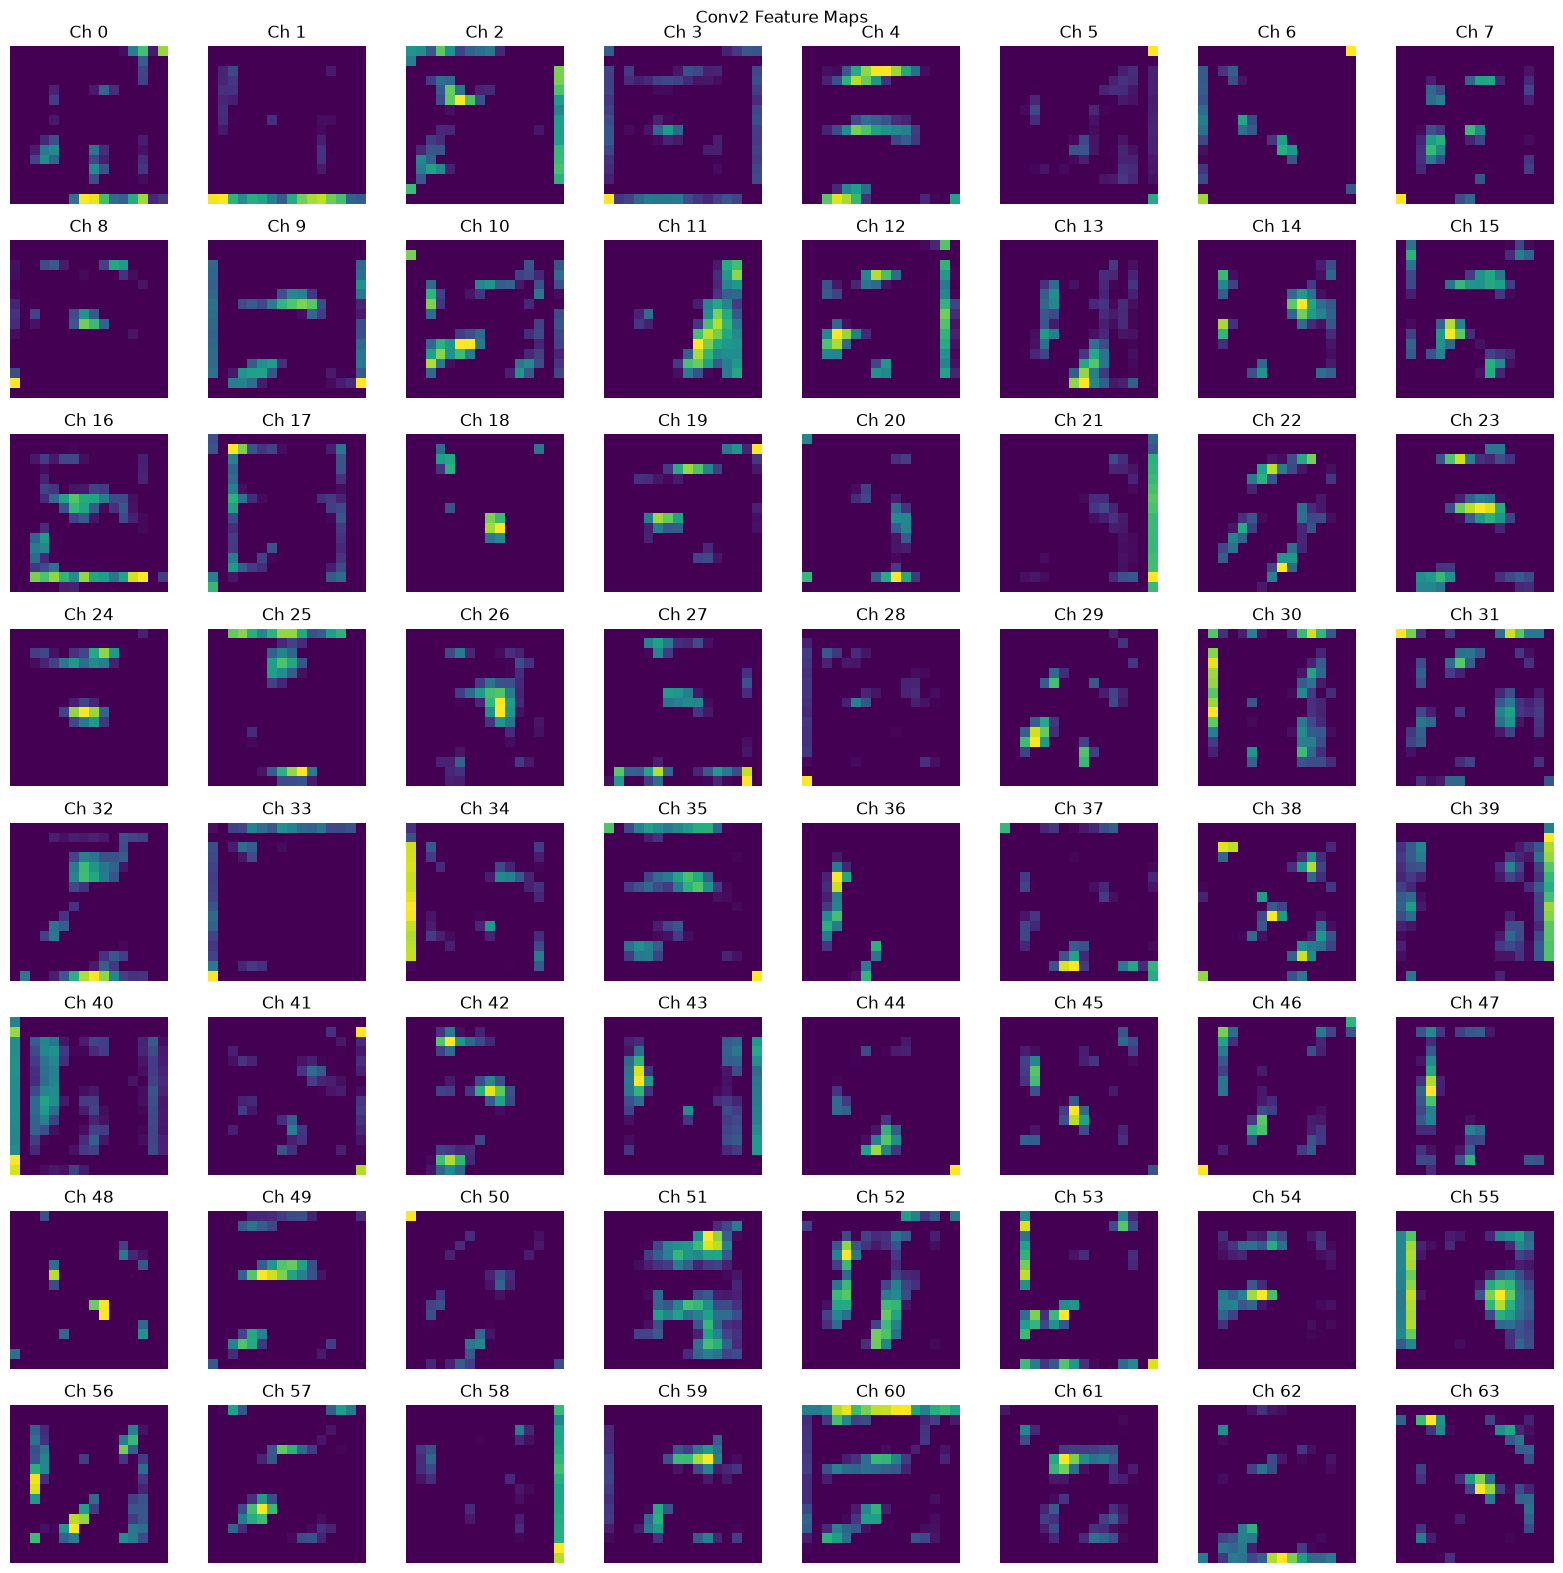

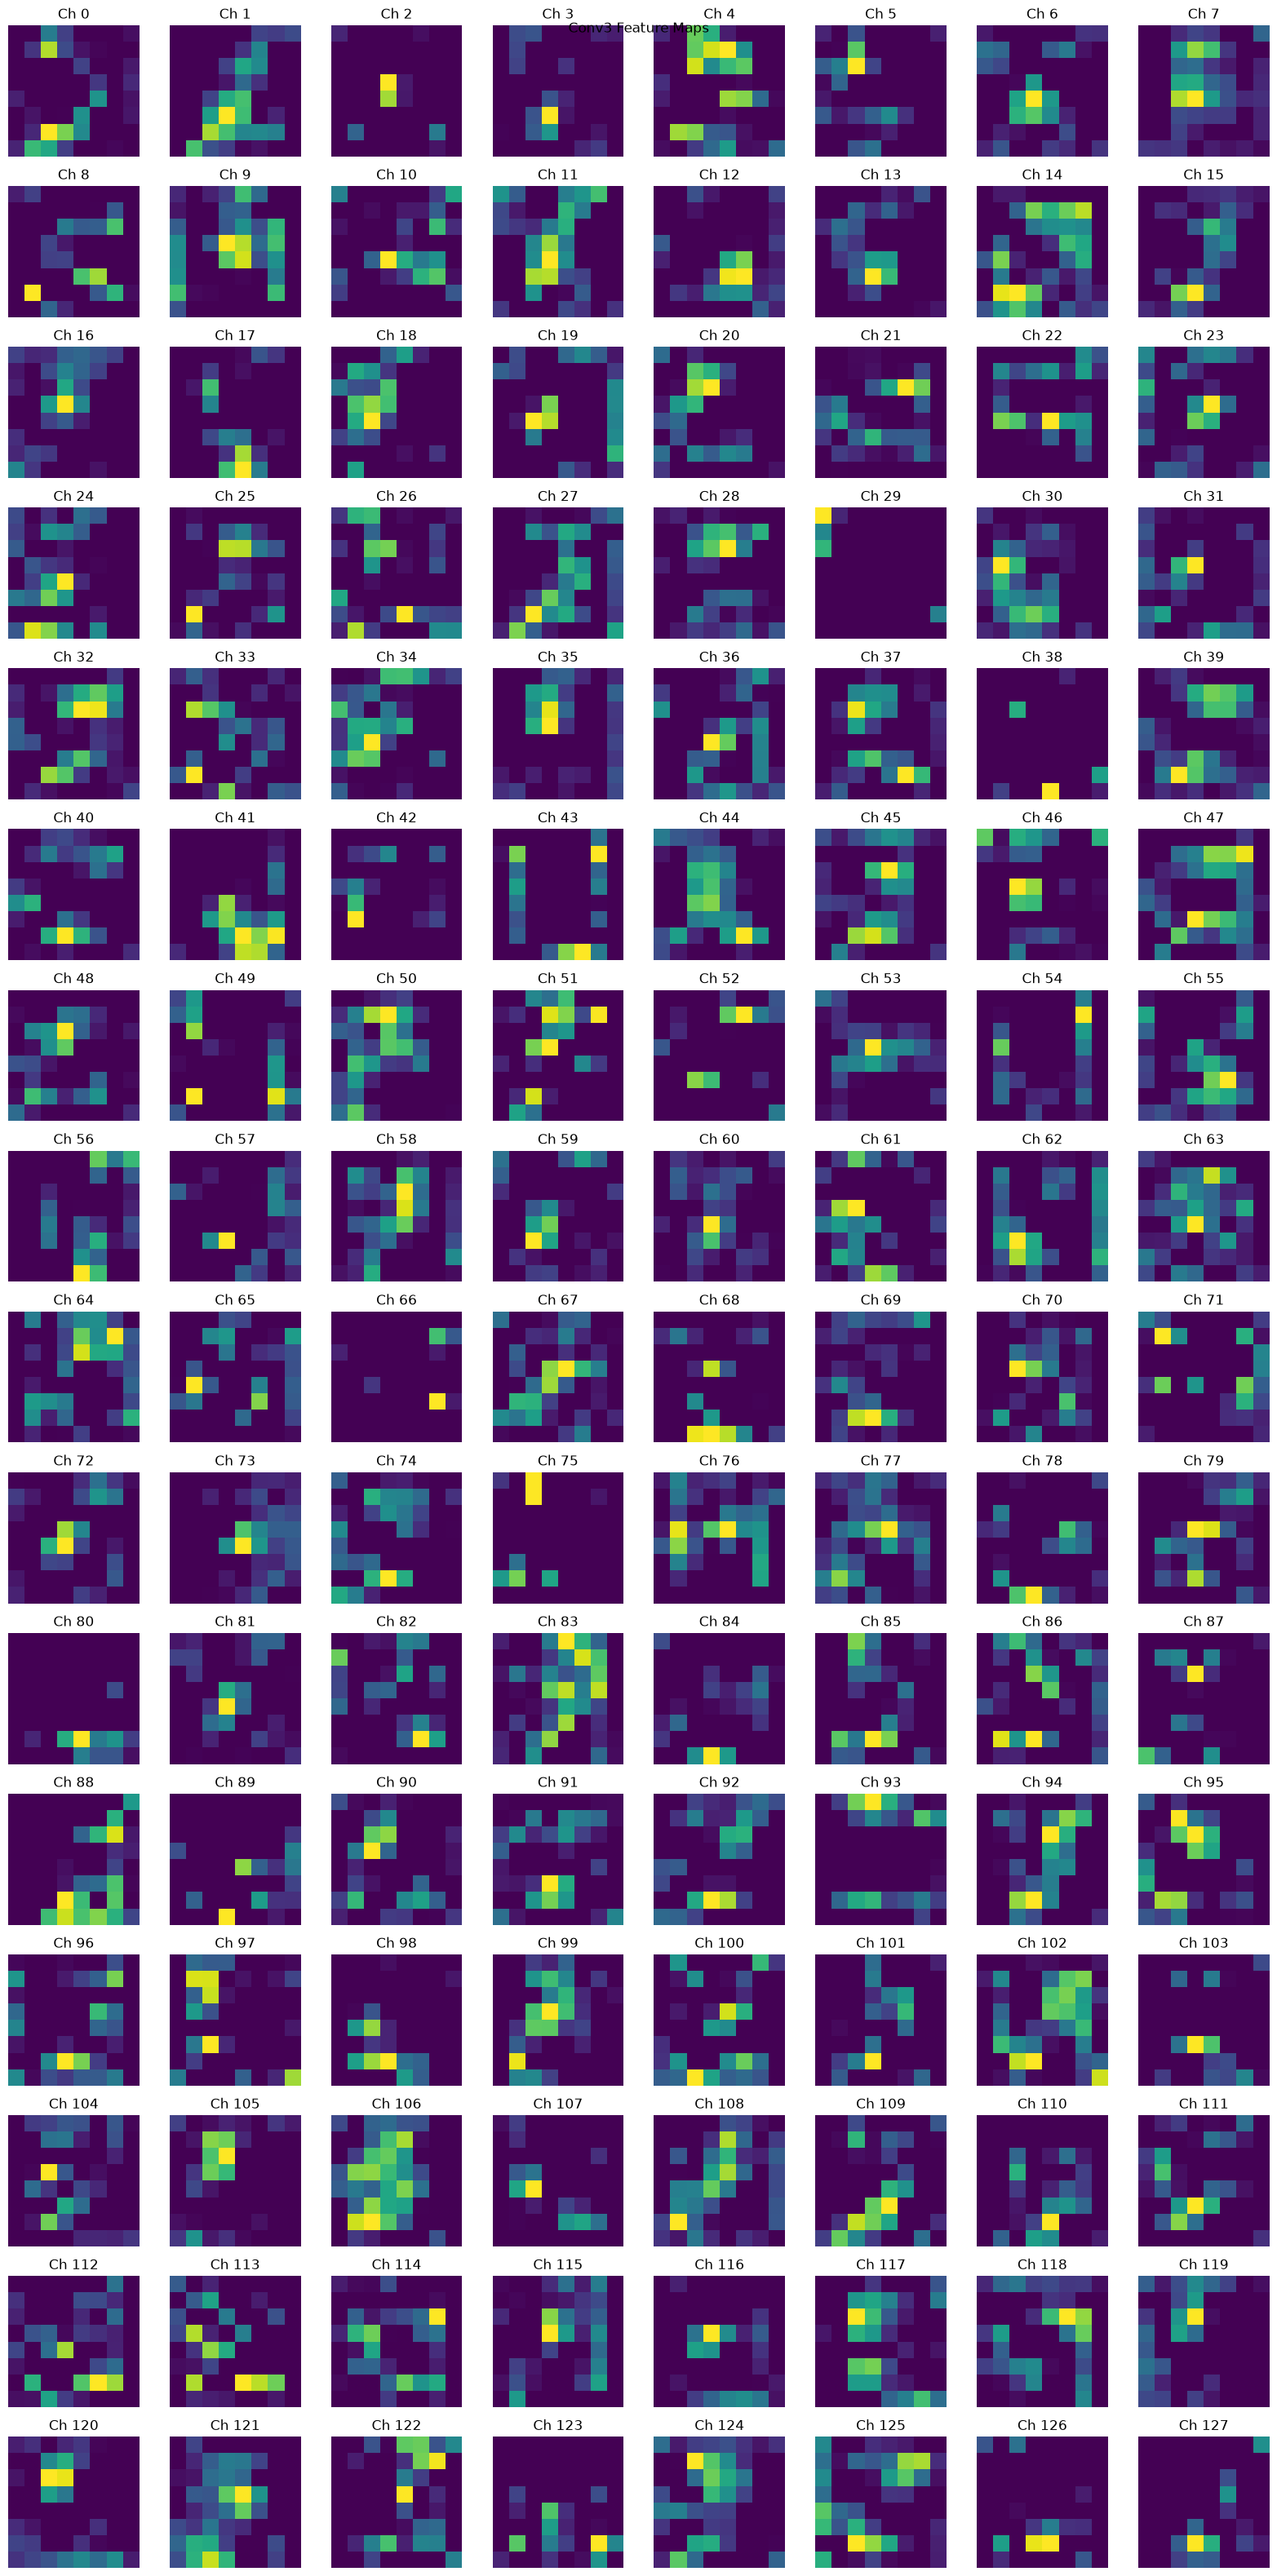

In [ ]:
plot_feature_maps(feature_map1, 'Conv1 Feature Maps')
plot_feature_maps(feature_map2, 'Conv2 Feature Maps')
plot_feature_maps(feature_map3, 'Conv3 Feature Maps')

In [ ]:
# grad- CAM 전사
import torch
import torch.nn.functional as F

def grad_cam(model, image, target_layer, target_class=None):

    model.eval()

    feature_maps = {}
    gradients = {}

    # 1. Feature Map 및 Gradient 수집
    def save_activation(module, inputs, output):
        feature_maps['value'] = output.detach()

        def save_gradient(grad):
            gradients['value'] = grad.detach()

        output.register_hook(save_gradient)

    # 2. Forward Hook 등록
    handle = target_layer.register_forward_hook(save_activation)

    try:
        with torch.enable_grad():

            image = image.detach().requires_grad_(True)

            # 3. Forward
            model.zero_grad(set_to_none=True)

            y_hat = model(image)
            pred_class = y_hat.argmax(dim=1).item()

            if target_class is None:
                target_class = pred_class

            # 4. 특정 클래스의 logit 선택
            score = y_hat[0, target_class]

            # 5. Backward
            score.backward()

            # 6. Feature Map과 Gradient 불러오기
            A = feature_maps['value']
            G = gradients['value']

            # 7. 채널별 Gradient 평균
            weights = G.mean(dim=(2, 3), keepdim=True)

            # 8. 가중합 및 ReLU
            cam = (weights * A).sum(dim=1, keepdim=True)
            cam = F.relu(cam)

            # 9. 원본 이미지 크기로 확대
            cam = F.interpolate(
                cam,
                size=image.shape[2:],
                mode='bilinear',
                align_corners=False
            )

            # 10. Heatmap 정규화
            cam = cam - cam.min()
            cam = cam / (cam.max() + 1e-8)

            cam = cam[0, 0].detach().cpu()

    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)

    return cam, pred_class

In [ ]:
cam, pred_label = grad_cam(
    model=load_model,
    image=image,
    target_layer=load_model.conv3
)

print('True Label:', true_label)
print('Pred Label:', pred_label)
print('CAM Shape :', cam.shape)

True Label: 5
Pred Label: 5
CAM Shape : torch.Size([32, 32])


In [ ]:
# grad - CAM 시각화
def plot_grad_cam(image, cam, true_label, pred_label):

    img = image[0].detach().cpu().permute(1, 2, 0)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))

    # 원본 이미지
    ax[0].imshow(img)
    ax[0].set_title(f'True: {true_label}, Pred: {pred_label}')

    # Heatmap
    ax[1].imshow(cam, cmap='jet', vmin=0, vmax=1)
    ax[1].set_title('Grad-CAM')

    # Overlay
    ax[2].imshow(img)
    ax[2].imshow(
        cam,
        cmap='jet',
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    ax[2].set_title('Grad-CAM Overlay')

    for a in ax:
        a.axis('off')

    plt.tight_layout()
    plt.show()

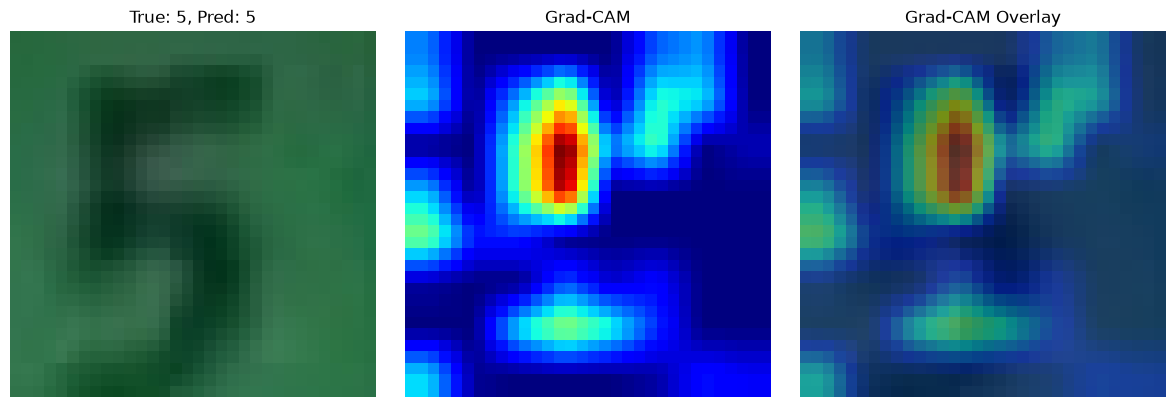

In [ ]:
plot_grad_cam(image, cam, true_label, pred_label)

#### t-SNE 추가